Task 1 - Importing all required libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats
from scipy.stats import skew
%matplotlib inline

In [ ]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (12,8)

Task2 - Load the Data

The advertisement dataset captures sales revenue generated with respect adveertisement across multiple channel like TV, radio and newspaper.


In [ ]:
df = pd.read_csv('Advertising.csv')

In [ ]:
df.head(10)

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
5,8.7,48.9,75.0,7.2
6,57.5,32.8,23.5,11.8
7,120.2,19.6,11.6,13.2
8,8.6,2.1,1.0,4.8
9,199.8,2.6,21.2,10.6




```
# This is formatted as code
```

Task 3 - Relationship between features and response


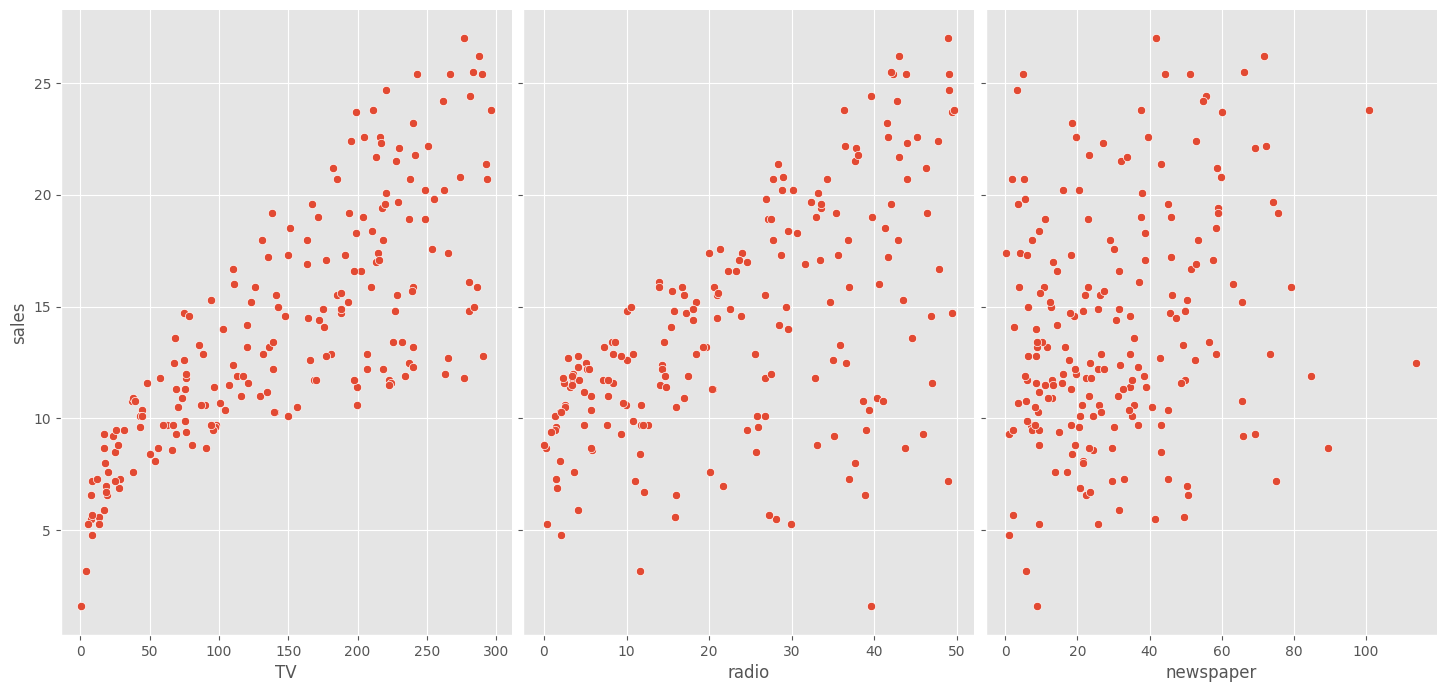

In [ ]:
sns.pairplot(df, x_vars = ['TV', 'radio', 'newspaper'], y_vars='sales', height=7, aspect=0.7)

Task 4 - Build Multiple Linear Regression Model - Estimating Coefficients


In [ ]:
from sklearn.linear_model import LinearRegression
x = df.drop('sales', axis=1)
y = df['sales']

lm1 = LinearRegression()
lm1.fit(x,y)

print(lm1.intercept_)
print(lm1.coef_)

2.938889369459412
[ 0.04576465  0.18853002 -0.00103749]


In [ ]:
#store feature name
feature_name = ['TV', 'radio', 'newspaper']
#get regression coeffiecient
cofficient = lm1.coef_
#creating a dict to map each column to its coeffiecient
feature_cofficient = dict(zip(feature_name, cofficient))
#display
feature_cofficient

{'TV': np.float64(0.0457646454553976),
 'radio': np.float64(0.18853001691820448),
 'newspaper': np.float64(-0.0010374930424763285)}

<Axes: >

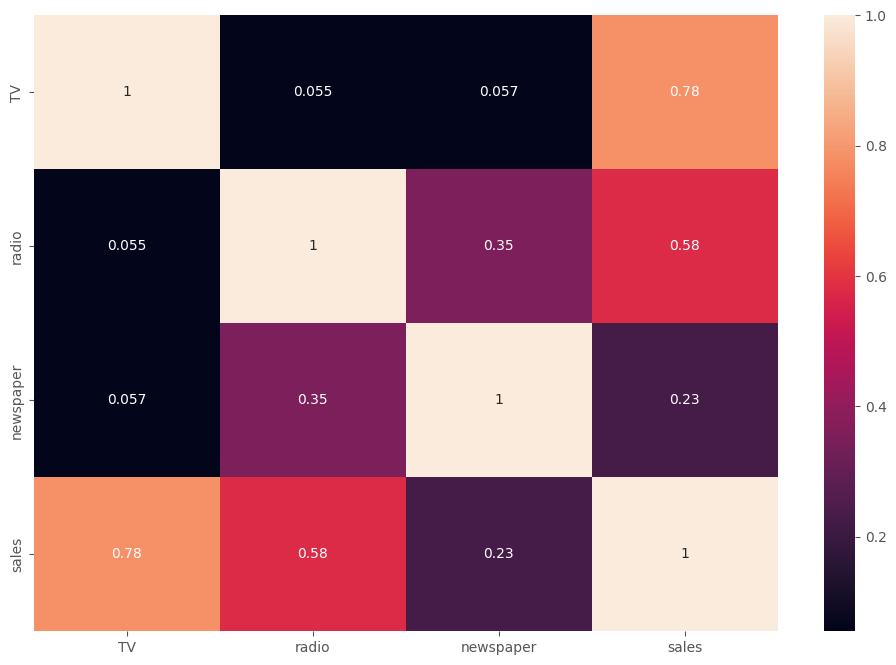

In [ ]:
sns.heatmap(df.corr(), annot=True)

Task5 - Feature selection


In [ ]:
from sklearn.metrics import r2_score
#Model1 - Using TV and Radio
X_tv_radio = df[['TV', 'radio']]

#Initializing
lm2 = LinearRegression()

#Tain model on full data set(fitting)
lm2.fit(X_tv_radio, y)

#Predicting the Sales
lm2_pred = lm2.predict(X_tv_radio)

#calculate R2 score for model evaluation
R2_tv_radio = r2_score(y, lm2_pred)

print("R2 score using tv and radio", R2_tv_radio)


R2 score using tv and radio 0.8971942610828957


In [ ]:
#Model2 - Using Tv, radio and newspaper

X_all_feature = df[['TV', 'radio', 'newspaper']]

lm3 = LinearRegression()

lm3.fit(X_all_feature, y)

lm3_pred = lm3.predict(X_all_feature)

R2_all_feature = r2_score(y, lm3_pred)

print("R3 score using all feature", R2_all_feature)


R3 score using all feature 0.8972106381789522


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

X = df.drop('sales', axis=1)
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

lm4 = LinearRegression()
lm4.fit(X_train, y_train)

lm4_pred = lm4.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, lm4_pred))
print(rmse)

r2_score_value = r2_score(y_test, lm4_pred)
print(r2_score_value)


1.4113417558581587
0.8927605914615384


Task 6 - Model Evaluation Using Train/Test Split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

X = df.drop('sales', axis=1)
Y = df['sales']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=1)
lm4 = LinearRegression()
lm4.fit(X_train,Y_train)

lm4_pred = lm4.predict(X_test)

rmse = np.sqrt(mean_squared_error(Y_test,lm4_pred))
print(rmse)

r2_score = r2_score(Y_test,lm4_pred)
print(r2_score)

from sklearn.metrics import r2_score
X = df.drop(['sales', 'newspaper'], axis=1)
Y = df['sales']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=1)
lm5 = LinearRegression()
lm5.fit(X_train,Y_train)
lm5_pred = lm5.predict(X_test)

rmse = np.sqrt(mean_squared_error(Y_test,lm5_pred))
print(rmse)

r2_score = r2_score(Y_test,lm5_pred)
print(r2_score)

1.4113417558581587
0.8927605914615384
1.398292489077775
0.8947344950027066


Task 7 - Model diagnostic

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


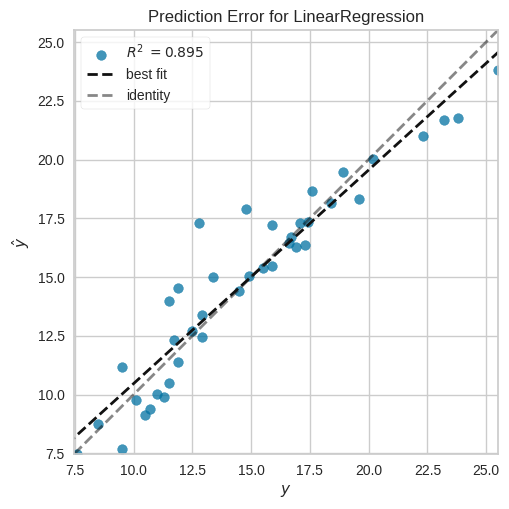

<Axes: title={'center': 'Prediction Error for LinearRegression'}, xlabel='$y$', ylabel='$\\hat{y}$'>

In [ ]:
from yellowbrick.regressor import ResidualsPlot, PredictionError
visulaizer = PredictionError(lm5).fit(X_train, y_train)
visulaizer.score(X_test, y_test)
visulaizer.show()


Task 8 - Interaction Effect

In [ ]:
from sklearn.metrics import r2_score

#creating interaction feature
df['tv_radio_interaction'] = df['radio']*df['TV']

#select the feature including interaction term
X = df[['TV', 'radio', 'tv_radio_interaction']]
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1)

#training the interaction model

interaction_model = LinearRegression()
interaction_model.fit(X_train, y_train)

y_test_prediciton = interaction_model.predict(X_test)

print("RMSE: ", np.sqrt(mean_squared_error(y_test, y_test_prediciton)))
print("R2 score: ", r2_score(y_test, y_test_prediciton))

RMSE:  0.7011871137164328
R2 score:  0.978973681468126


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


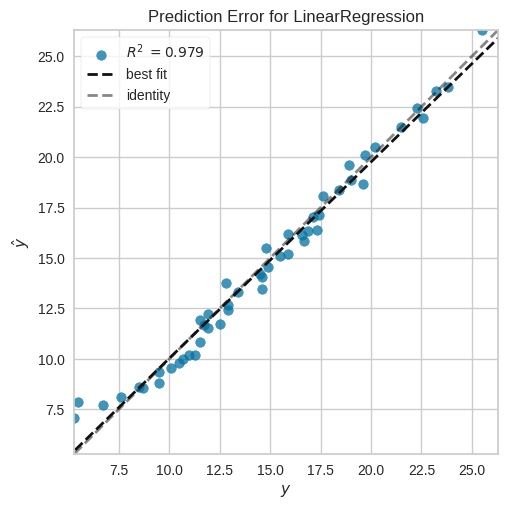

<Axes: title={'center': 'Prediction Error for LinearRegression'}, xlabel='$y$', ylabel='$\\hat{y}$'>

In [ ]:
#visualising prediction performance
from yellowbrick.regressor import ResidualsPlot, PredictionError
visulaizer = PredictionError(interaction_model).fit(X_train, y_train)
visulaizer.score(X_test, y_test)
visulaizer.show()

**Conclusion**

Through this project, I learned how to work with a real dataset and perform basic data analysis using Python. I learned how to explore data, visualize relationships, and build a simple Linear Regression model to predict sales. I also learned how to compare different models using evaluation metrics such as RMSE and R² score. By experimenting with different feature combinations, I understood the importance of selecting relevant features for improving prediction accuracy.



From the analysis, it was found that TV and radio advertisements have a strong influence on sales, while newspaper advertisements have minimal impact. The results showed that models using only TV and radio performed better than models using all features. Adding an interaction term between TV and radio further improved model performance. Overall, the data indicates that TV and radio advertising contributes more significantly to sales compared to newspaper advertising.





